# Assembly of a capsid with N = 12 subunits

This notebook simulates the assembly of a dodecahedral model (N = 12) from the kinetic master equation, which describes the time evolution of the subunits of a capsid. N = 12 is used to reproduce the case studied by Zlotnick.

References on which the code is based:

* Hagan, M. F. (2014). Modeling viral capsid assembly. *Advances in Chemical Physics*, 155, 1-68.
* Zlotnick, A. (1994). To build a virus capsid: an equilibrium model of the self assembly of polyhedral protein complexes. *Journal of Molecular Biology*, 241(1), 59-67.
* Endres, D., & Zlotnick, A. (2002). Model-based analysis of assembly kinetics for virus capsids or other spherical polymers. *Biophysical Journal*, 83(2), 1217-1230.

The notation follows Hagan (2014) and Endres and Zlotnick (2002).

# Equations of the model

Notation:

* $N$: number of subunits of the complete capsid.
* $M$: monomer concentration.
* $I_n$: concentration of the intermediate with $n$ subunits.
* $I_N$: concentration of the complete capsid ($N$ subunits).
* $f_n$: association rate of a monomer to an intermediate of size $n$. It is written $f_n = s_n^f f$, where $f$ is the baseline association constant and $s_n^f$ is the geometric statistical factor, which counts the available sites to which the monomer can bind.
* $b_n$: dissociation rate. It is written $b_n = s_n^b b_n^*$, where $b_n^*$ is the baseline dissociation constant and $s_n^b$ is the statistical factor that counts the subunits that can detach from the capsid.
* Hagan (2014) writes $b_n^* = f\,e^{\Delta G_n^{contact}/k_B T} = f\,e^{\Delta p\,\epsilon_b}$.
* $\Delta p = p_n - p_{n-1}$: number of new contacts formed when going from $n-1$ to $n$.
* $\epsilon_b = \Delta G_n^{contact}/k_B T$: free energy of one protein–protein contact, in units of $k_B T$.

Equations:

* Net flux of the transition $n \to n+1$:

  $J_n = f_n I_n M - b_{n+1} I_{n+1}$

* Intermediates, for $1 < n < N$:

  $dI_n/dt = J_{n-1} - J_n$

* Monomer. At the start there is only unassembled monomer ($n = 1$):

  $dM/dt = -2J_1 - \sum_{n=2}^{N-1} J_n$

* Complete capsid. When it is completed ($n = N$) growth stops, that is, $J_N = 0$:

  $dI_N/dt = J_{N-1}$

Parameters of the simulation:

* `f_base = 1e5`: baseline association constant, in M⁻¹ s⁻¹.
* `total_monomer_conc = 50e-6`: initial monomer concentration, in M.
* $\epsilon_b = -5.0$: free energy of one protein–protein contact, dimensionless (in multiples of $k_B T$, as in Hagan 2014).
* $\Delta p$: number of new contacts per step, taken from the table of Zlotnick (1994).
* $s_f$: statistical (geometric) factor for association.
* $s_b$: statistical factor for dissociation.

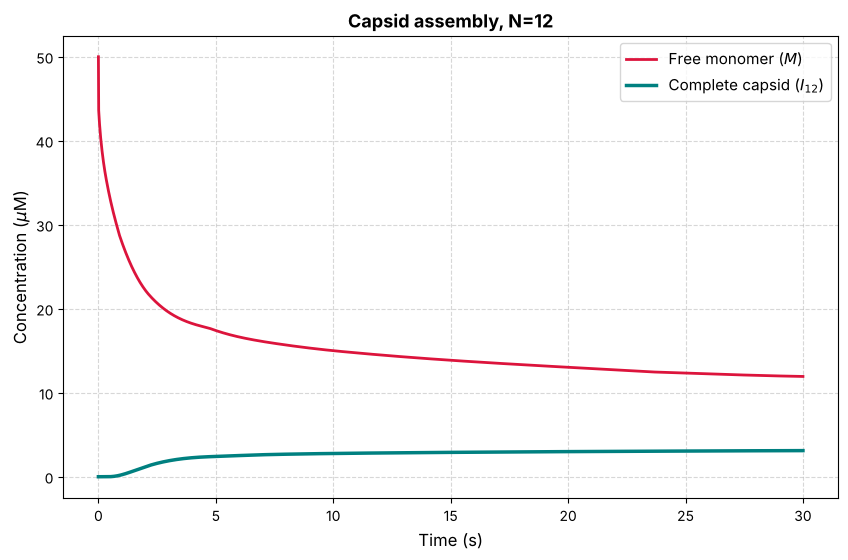

In [1]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt


# ---- system of differential equations ----------------------------------
def capsid_equations(t, y, f, epsilon_b, s_f, s_b, delta_p, N):
    """
    Right-hand side of the assembly ODE system.

    y[0]     = [M]   (monomer)
    y[1:]    = [I_n] (intermediates); y[N-1] = [I_N] (complete capsid)
    b_star   = b* (baseline dissociation rate, in 1/s)
    J[n]     = flux of the transition n -> n+1
    s_f[n]   = statistical factor for association
    s_b[n]   = statistical factor for dissociation
    """
    dydt = np.zeros(N)


    # baseline dissociation rate b*, in 1/s
    b_star = f * np.exp(delta_p * epsilon_b)

    # Net flux: J[n] is the flux of the transition from n to n+1
    J = np.zeros(N + 1)

    # going from n=1 to n=2
    J[1] = (s_f[1] * f * y[0]**2) - (s_b[2] * b_star[2] * y[1])

    # elongation from n=2 to N-1
    for n in range(2, N):
        J[n] = (s_f[n] * f * y[n-1] * y[0]) - (s_b[n+1] * b_star[n+1] * y[n])

    # monomer equation dM/dt
    dydt[0] = -2 * J[1] - np.sum(J[2:N])

    # intermediate equations dI_n/dt, from n=2 to N-1
    for n in range(2, N):
        i = n - 1  # 0-indexed mapping
        dydt[i] = J[n-1] - J[n]

    # complete-capsid equation dI_N/dt (n=N)
    dydt[N-1] = J[N-1]

    return dydt
#-------------------------------------------------------------------------



# Simulation parameters
# -----------------------------------------------------------------
N = 12                     # number of subunits of the final capsid
total_monomer_conc = 5e-5  # 50 µM (in M), initial concentration
f_base = 1e5               # baseline association constant (1/(M s))

# contact energy (in k_B T)
epsilon_b = -5.0

# geometric parameters (Table 1 of Zlotnick 1994); they can be replaced by a function
delta_p = np.array([0, 0, 1, 2, 2, 2, 3, 2, 3, 3, 3, 4, 5])
s_f     = np.array([0, 10, 2, 3, 4, 1, 5, 2, 2, 3, 2, 1, 0])
s_b     = np.array([0, 0, 1, 3, 2, 2, 5, 1, 4, 3, 2, 5, 12])

# initial condition: only monomer is present
y = np.zeros(N)
y[0] = total_monomer_conc

# integration from 0 to 30 s, with 2500 output points
t_range = (0.0, 30.0)
t = np.linspace(t_range[0], t_range[1], 2500)

# solution of the system of differential equations
solution = solve_ivp(
    capsid_equations,
    t_range,
    y,
    args=(f_base, epsilon_b, s_f, s_b, delta_p, N),
    t_eval=t,
    method='Radau'
)


# plots and results
# --------------------------------------
plt.figure(figsize=(10, 6))

# concentrations in µM
plt.plot(solution.t, solution.y[0] * 1e6, label='Free monomer ($M$)', color='crimson', lw=2)
#plt.plot(solution.t, solution.y[5] * 1e6, label='Mid-Size Intermediates ($I_6$)#', color='darkorange', linestyle='--')
plt.plot(solution.t, solution.y[N-1] * 1e6, label='Complete capsid ($I_{12}$)', color='teal', lw=2.5)

plt.xlabel('Time (s)', fontsize=12)
plt.ylabel(r'Concentration ($\mu$M)', fontsize=12)
plt.title('Capsid assembly, N=12', fontsize=13, fontweight='bold')
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.legend(fontsize=11)
plt.show()